In [131]:
%load_ext autoreload
%autoreload 2
%load_ext jupyter_black

import sys
from pathlib import Path

scripts_path = str(Path.cwd().parents[1]) + "/scripts/"
if scripts_path not in sys.path:
    sys.path.insert(0, scripts_path)

from Config import (
    CATALOGUE_JEROEN,
    POSITIONS_F115W,
    GAIA_CATALOGUE,
    MPLSTYLE,
    SB_PARAM_DIR,
    PHOT_DIR,
    PLOTS_DIR,
    LEVEL2_DIR,
    LEVEL3_DIR,
    STARBUG2_BIN,
)
from astropy.io import fits
import phot_toolkit as PTK
import photometric_pipeline as PPL
import plot_toolkit as PLOT

import numpy as np
import matplotlib.pyplot as plt 
matplotlib.gridspec as gridspec
from matplotlib.colors import to_rgb
from astropy.coordinates import SkyCoord
import matplotlib.pyplot as plt
import astropy.units as u

# if MPLSTYLE.exists():
#     plt.style.use(str(MPLSTYLE))

working_directory = f"{LEVEL2_DIR}/mastDownload/JWST"
PHOTOMETRIC_pipeline = PPL.Pipeline_level_2_data(working_directory=working_directory)

SyntaxError: invalid syntax (2229144363.py, line 31)

In [159]:
with fits.open("jw01227002001_02105_00001_nrcalong_cal_1overf_jhat-psf-zp.fits") as hdu:
    print(hdu.info())
    print(list(hdu[1].header))
    data = hdu[1].data

Filename: jw01227002001_02105_00001_nrcalong_cal_1overf_jhat-psf-zp.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1                1 BinTableHDU    139   62404R x 15C   [7A, D, D, D, D, D, I, D, D, D, D, D, D, D, D]   
None
['XTENSION', 'BITPIX', 'NAXIS', 'NAXIS1', 'NAXIS2', 'PCOUNT', 'GCOUNT', 'TFIELDS', 'TTYPE1', 'TFORM1', 'TTYPE2', 'TFORM2', 'TTYPE3', 'TFORM3', 'TTYPE4', 'TFORM4', 'TTYPE5', 'TFORM5', 'TTYPE6', 'TFORM6', 'TTYPE7', 'TFORM7', 'TZERO7', 'TTYPE8', 'TFORM8', 'TTYPE9', 'TFORM9', 'TTYPE10', 'TFORM10', 'TTYPE11', 'TFORM11', 'TTYPE12', 'TFORM12', 'TTYPE13', 'TFORM13', 'TTYPE14', 'TFORM14', 'TTYPE15', 'TFORM15', 'STARBUG', 'FILTER', 'PARAM', 'VERBOSE', 'OUTPUT', 'HDUNAME', 'FWHM', 'SIGSKY', 'SIGSRC', 'DOBGD2D', 'DOCONVL', 'CLEANSRC', 'SHARP_LO', 'SHARP_HI', 'RICKER_R', 'APPHOT_R', 'SKY_RIN', 'SKY_ROUT', 'BGD_R', 'BOX_SIZE', 'AP_FILE', 'BGD_FILE', 'PSF_FILE', 'USE_WCS', 'ZP_MAG', 'CRIT_SEP', 'PSF_SIZE', '

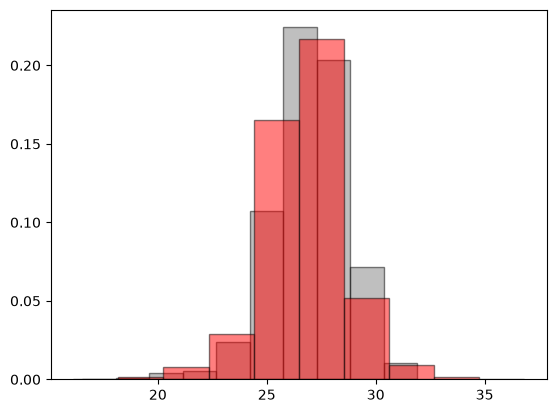

In [160]:
plt.hist(data["ap_F444W"], color="gray", edgecolor="black", alpha=0.5, density=True)
plt.hist(data["F444W"], color="red", edgecolor="black", alpha=0.5, density=True)
plt.show()

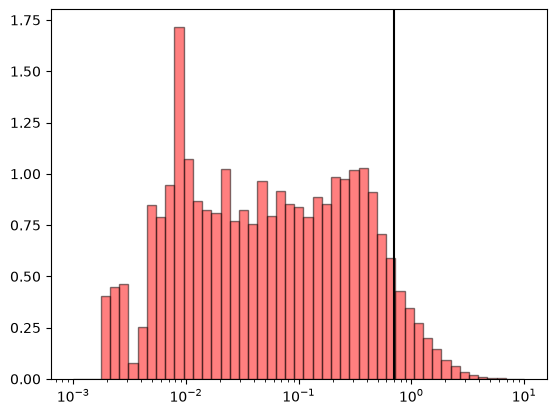

In [161]:
bins = np.logspace(-3, 1)

plt.hist(
    data["eF444W"], bins=bins, color="red", edgecolor="black", alpha=0.5, density=True
)
plt.xscale("log")

plt.axvline(0.7, c="black")
plt.show()

In [162]:
from astropy.table import Table

Table(data).keys()

['Catalogue_Number',
 'x_init',
 'y_init',
 'RA',
 'DEC',
 'ap_F444W',
 'flag',
 'x_fit',
 'y_fit',
 'flux',
 'eflux',
 'xydev',
 'qfit',
 'F444W',
 'eF444W']

In [163]:
import numpy as np
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.table import Table, hstack


def match_catalogs(cat1, cat2, ra_col="RA", dec_col="DEC", max_sep=0.05 * u.arcsec):
    """
    Cross-match a shallow catalog to a deep catalog using
    SkyCoord.match_to_catalog_sky.
    """
    c_1 = SkyCoord(
        ra=np.asarray(cat1[ra_col]) * u.deg, dec=np.asarray(cat1[dec_col]) * u.deg
    )
    c_2 = SkyCoord(
        ra=np.asarray(cat2[ra_col]) * u.deg, dec=np.asarray(cat2[dec_col]) * u.deg
    )

    # For each shallow source: index of nearest deep source, and the separation
    idx, sep2d, _ = c_1.match_to_catalog_sky(c_2)

    good = sep2d < max_sep

    idx_shallow = np.where(good)[0]
    idx_deep = idx[good]

    # Build the joined output table
    cat1_m = cat1[idx_shallow]
    cat2_m = cat2[idx_deep]
    cat2_m.rename_columns(
        cat2_m.colnames, [f"{n}_CATALOGUE_JEROEN" for n in cat2_m.colnames]
    )

    matched = hstack([cat1_m, cat2_m], join_type="exact")
    matched["sep_arcsec"] = sep2d[good].to(u.arcsec).value
    return matched, idx_shallow, idx_deep


Catalogue = PTK.Read_Catalogue()

matched, idx_shallow, idx_deep = match_catalogs(
    cat1=Table(data[(np.isfinite(data["F444W"])) & (data["eF444w"] < 0.7)]),
    cat2=Table(Catalogue.cat_data),
)

In [ ]:
with fits.open(
    LEVEL2_DIR
    + "/mastDownload/JWST/jw01227002001_02105_00001_nrcalong/jw01227002001_02105_00001_nrcalong_cal.fits"
) as hdu:
    hdu.info()
    test = hdu[1].header
    PHOTMJSR = test["PHOTMJSR"]
    PIXAR_SR = test["PIXAR_SR"]

Filename: /net/vdesk/data2/slagter/JWST_NIRCAM_#1227_level_2/mastDownload/JWST/jw01227002001_02105_00001_nrcalong/jw01227002001_02105_00001_nrcalong_cal.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     263   ()      
  1  SCI           1 ImageHDU       156   (2048, 2048)   float32   
  2  ERR           1 ImageHDU        10   (2048, 2048)   float32   
  3  DQ            1 ImageHDU        11   (2048, 2048)   int32 (rescales to uint32)   
  4  AREA          1 ImageHDU         9   (2048, 2048)   float32   
  5  VAR_POISSON    1 ImageHDU         9   (2048, 2048)   float32   
  6  VAR_RNOISE    1 ImageHDU         9   (2048, 2048)   float32   
  7  VAR_FLAT      1 ImageHDU         9   (2048, 2048)   float32   
  8  ASDF          1 BinTableHDU     11   1R x 1C   [61925B]   
0.39100000262260437
9.30255546804624e-14


In [ ]:
import os

os.environ["CRDS_PATH"] = os.path.expanduser("~/crds_cache")
os.environ["CRDS_CONTEXT"] = "jwst_1584.pmap"
os.environ["CRDS_SERVER_URL"] = "https://jwst-crds.stsci.edu"
import crds
from stdatamodels.jwst.datamodels import ABVegaOffsetModel

header_selectors = {
    "INSTRUME": "NIRCAM",
    "DETECTOR": "NRCA1",
    "PUPIL": "CLEAR",
    "DATE-OBS": "2026-11-01",
    "TIME-OBS": "12:00:00",
}

reffile_path = crds.getreferences(
    header_selectors, reftypes=["abvegaoffset"], context="jwst_1584.pmap"
)["abvegaoffset"]

print(f"Using reference file: {reffile_path}")


with ABVegaOffsetModel(reffile_path) as model:
    offset_table = model.abvega_offset
    # print(offset_table)

M_ab_to_M_vega_offset = 3.3893974

Using reference file: /home/slagter/crds_cache/references/jwst/nircam/jwst_nircam_abvegaoffset_0003.asdf


In [184]:
flux_dns = matched["flux"]
flux_physical = flux_dns * PHOTMJSR
M_Ab = -6.10 - 2.5 * np.log10(flux_physical * PIXAR_SR)
M_Vega = M_Ab + M_ab_to_M_vega_offset

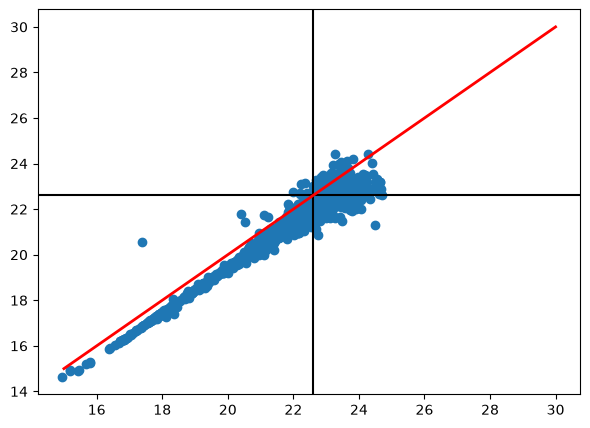

In [192]:
plt.figure(figsize=(7, 5))
plt.scatter(
    M_Vega + 8.9,
    matched["F444W_CATALOGUE_JEROEN"],
)
plt.axvline(22.60, c="black", label="Completeness limit")
plt.axhline(22.60, c="black", label="Completeness limit")
plt.plot(np.linspace(15, 30), np.linspace(15, 30), c="red", lw=2)

# plt.xlim(14, 25)
# plt.ylim(15, 30)

# plt.ylim(-1, 1)
plt.show()

In [ ]:

cmd_bgd = [
    str(STARBUG2_BIN),
    "-B",  # Alleen achtergrondbepaling runnen
    
]

PHOTOMETRIC_pipeline._run_starbug2(cmd_bgd, toggle_sb_output_txt=True)


SyntaxError: unterminated string literal (detected at line 4) (3976211152.py, line 4)

In [191]:
print(
    LEVEL2_DIR
    + "/mastDownload/JWST/jw01227002001_02105_00001_nrcalong/jw01227002001_02105_00001_nrcalong_cal.fits"
)
print(STARBUG2_BIN)

/net/vdesk/data2/slagter/JWST_NIRCAM_#1227_level_2/mastDownload/JWST/jw01227002001_02105_00001_nrcalong/jw01227002001_02105_00001_nrcalong_cal.fits
/home/lslagter/scratch/lslagter/MSC_project/STRW-MSC/STARBUG2_venv/bin/starbug2
